In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.001411831220003403 + 0.0005787856133305285im -0.008671361835185607 - 0.0007491327092361294im … 0.003305494533705686 - 0.0019306434322871834im 5.87413498425158e-5 + 0.002431327497249616im; 0.0014191654104147024 + 0.001049916835295992im 0.002445712105167415 - 0.0019562112243708477im … -0.0005117229551291166 - 0.002978996969463956im 0.0007873387173398723 + 0.0016287714585968244im; -0.004662250012845012 + 0.0028822703716395864im -0.0030865332089832745 + 0.002546202282809463im … 0.0013661609100618477 - 0.002575951547637783im -0.0024019287632235584 - 0.0019146100621993834im;;; 0.00022858273079768337 - 0.0026607012358823142im -0.0034264286340707226 - 0.000671078228313901im … -0.0008664659831088645 + 0.0017680845676390062im 0.0010227642393485323 - 0.001821903110545924im; 0.0003672645829302879 + 0.0030199737435870834im 0.0004979000579458503 + 0.00018515006368066854im … -0.004249379182758799 + 0.0008926191416442317im 0

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[1.1384447927087053e-6 - 4.0589899459367063e-7im 8.657526491283308e-6 - 7.723916137494994e-6im … -2.668593343587713e-7 - 8.703621618878971e-6im -5.0923133756683465e-6 - 1.2067136653540248e-6im; 2.7500392820391485e-6 + 2.5090488918771725e-6im -3.486737430030814e-6 - 2.3164317267109716e-6im … 8.36882939315488e-6 + 6.203145726902268e-6im -5.708823541831486e-6 + 4.893967639359232e-7im; -5.5271159218562353e-8 + 3.3624229163318102e-6im 8.18369116021554e-6 - 4.520875013309655e-6im … 5.028430355105059e-6 - 1.2829298168823694e-5im 8.36758811538908e-6 + 1.0186033603311054e-5im;;; -2.671826536137126e-6 - 4.453723210014561e-6im -8.646314768414038e-7 - 1.9280067735546926e-6im … -6.671981811800121e-6 + 5.528962310029845e-6im -2.2721750784309895e-6 - 6.480031570757152e-6im; -7.03095816295489e-6 + 1.7192428017040003e-6im 9.089527826872835e-6 - 1.2178961827007802e-5im … -3.3824870628310673e-6 + 7.89900067280582e-7im 1.4091445659

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.4542372211116768 + 0.0im 1.556223412033176 + 0.0im 0.4944317546148081 + 0.0im -0.7906677325168993 + 0.0im; 1.12980661041124 + 0.0im -1.6001462589317632 + 0.0im 0.946622146549141 + 0.0im -0.4775537252546944 + 0.0im; 0.4653641661464667 + 0.0im 0.9534032562566549 + 0.0im 0.6745193859525633 + 0.0im -0.458929290241255 + 0.0im; -0.06572245430859676 + 0.0im -0.02043503906775147 + 0.0im -0.14907927106109126 + 0.0im -1.5860109127996456 + 0.0im]
 [1.415691625415732 + 0.0im -0.14409138625290238 + 0.0im -0.3309302905344367 + 0.0im -0.310273491988136 + 0.0im; -0.9391479426961564 + 0.0im 1.172373853156946 + 0.0im -1.0924682770319674 + 0.0im -2.084193526554025 + 0.0im; 1.4356256350728345 + 0.0im -1.5195845783970316 + 0.0im -0.48831252024817834 + 0.0im 1.7101439571533765 + 0.0im; 1.096746312790539 + 0.0im -0.880173695654037 + 0.0im -0.6567834891561138 + 0.0im 0.23440985499522202 + 0.0im]
 [-0.5471431030706995 + 0.0im -0.1242899318536072 + 0.0im 1.3844814145747402 + 

In [5]:
W=W*0.1
W1=W1*0.1
W2=W2*0.1
layer=PTC_Layer(hop,W)
layer1=PTC_Layer(hop,W1)
layer2=PTC_Layer(hop,W2)
layers = [layer, layer1,layer2]

3-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[-0.028167415542722608 + 0.0im 0.2188688186611767 + 0.0im -0.04434845320652445 + 0.0im -0.01654412441264512 + 0.0im; 0.07093843468362303 + 0.0im -0.13389943993104622 + 0.0im 0.10067413130156498 + 0.0im -0.06592565668982969 + 0.0im; 0.10889295160754811 + 0.0im -0.08619773408996945 + 0.0im -0.08312548545373023 + 0.0im 0.05672037948625315 + 0.0im; -0.048892980124129376 + 0.0im 0.024130588381024512 + 0.0im 0.1044917322351312 + 0.0im 0.13864032200810392 + 0.0im], [0.20257009471222764 + 0.0im 0.08386960621400194 + 0.0im 0.11656454720035647 + 0.0im -0.06233341685018854 + 0.0im; 0.12812744233267734 + 0.0im -0.19262352452816775 + 0.0im -0.04531507215052724 + 0.0im -0.051189114834019604 + 0.0im; -0.0025939168373286265 + 0.0im -0.02487112525385536 + 0.0im 0.13390447133948696 + 0.0im 0.05952632354482943 + 0.0im; -0.05025235743808315 + 0.0im 0.06474462356771436 + 0.0im 0.09389151174808795 + 0.0im 0.00042997157439187653 + 0.0im], [0.100661900750870

In [6]:
norm2(layer(x))

126102.32381218731 + 0.0im

In [7]:
opt=Adam()
opt.α=0.01

0.01

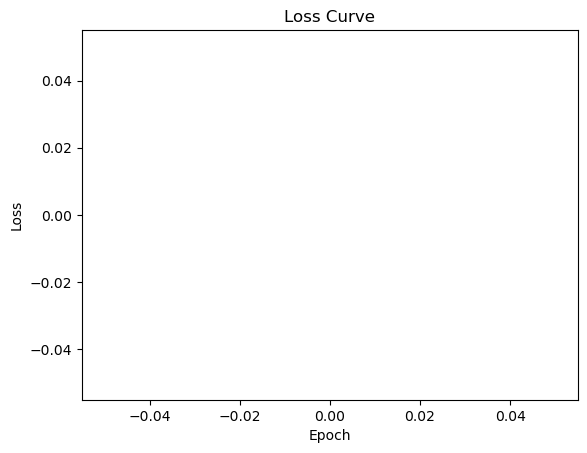

Epoch: 1, Loss: 1.4796421996136964 + 0.0im
Epoch: 2, Loss: 1.1387030298807879 + 0.0im
Epoch: 3, Loss: 0.8885611660391524 + 0.0im
Epoch: 4, Loss: 0.6992624405804557 + 0.0im
Epoch: 5, Loss: 0.5440335624036547 + 0.0im
Epoch: 6, Loss: 0.4295632170970276 + 0.0im
Epoch: 7, Loss: 0.3434438123608721 + 0.0im
Epoch: 8, Loss: 0.2814694418426156 + 0.0im
Epoch: 9, Loss: 0.23882239086985851 + 0.0im
Epoch: 10, Loss: 0.21364656266505702 + 0.0im
Epoch: 11, Loss: 0.19852943685923474 + 0.0im
Epoch: 12, Loss: 0.1885825896362058 + 0.0im
Epoch: 13, Loss: 0.18225948796346136 + 0.0im
Epoch: 14, Loss: 0.17822444792268785 + 0.0im
Epoch: 15, Loss: 0.17323557684820037 + 0.0im
Epoch: 16, Loss: 0.1678633504902757 + 0.0im
Epoch: 17, Loss: 0.1611556771370823 + 0.0im
Epoch: 18, Loss: 0.15250005775701142 + 0.0im
Epoch: 19, Loss: 0.14517987692416118 + 0.0im
Epoch: 20, Loss: 0.13614082369616307 + 0.0im
Epoch: 21, Loss: 0.12687392088617538 + 0.0im
Epoch: 22, Loss: 0.11601696385393297 + 0.0im
Epoch: 23, Loss: 0.10690891156

In [ ]:
train(opt,layers,x,t,D,epochs=700)


In [ ]:
Lossfunction(layer1(input),target)

2.269354308693939e-6 + 0.0im

In [ ]:
b = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
u = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(b)
gauss_distribution_fermion!(u)
u=deepcopy(b)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.3987158209220863 + 1.9591546982696681im 1.367528431213706 - 0.3993636159740443im … -0.08358594785761558 - 0.9057973413494895im 0.7275643435956592 + 0.6733835290640207im; -0.3958004734347832 + 0.49061817983484846im 1.742877833401898 - 0.4050913165295281im … 0.3884296206576375 - 0.6097193910064675im -0.23694715229034202 - 0.18833796603927866im; -1.0507411153849349 - 0.3411400949248552im 0.4102466924832127 - 0.7276547447799356im … -1.210652353588221 + 0.8812820634768318im 0.1546824174118781 + 0.05894499434736925im;;; 0.32885164739726924 - 0.26938918667244993im -0.8533905901505083 - 0.03536155953107787im … -1.0915026263351553 - 0.2898521851305611im 0.3212095026218155 - 0.4945310943640755im; 0.3912701532831905 - 0.7039897658859663im 1.0657075156347542 + 0.8960534276886419im … -1.0325197613760986 - 0.11623991490311648im -1.3773304631150654 - 0.09781054389420184im; -0.11153241034015486 + 0.003687700223505585im -0.2

In [ ]:
@save "PTC_weight.jld2" W  

In [ ]:
source=Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
source[1,1,1,1,1,1]=1


1

In [ ]:
gmres(b,D,source)

Converged at 2-9-th step. eps: 6.280350277848584e-11


In [ ]:
M=[layer1]

1-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[-0.27154547429851006 - 0.33668932093921866im -0.10023769265395646 - 0.11265313378461875im 0.06896046107894052 - 0.1344779498771988im 0.14662633643088532 + 0.007530099451302845im; -0.0056480026462422655 - 0.1621909746001587im -0.08998580687357126 - 0.12845177870139213im 0.000668776609793138 - 0.0348663659912481im 0.16735141734707012 + 0.21955195403406708im; -0.11094279710090127 - 0.07976294862645653im -0.05327196092468354 - 0.036716840343179305im -0.06415332067321074 - 0.05415434609212396im -0.00833137129900664 + 0.0851008688784282im; -0.031468709038913786 + 0.08301669986445256im -0.11275495426130876 + 0.23067448522404152im 0.10847753116122073 + 0.14197129022979088im -0.11655084129897399 - 0.06813706853326572im], [0.046050998639346814 - 0.015256655136207808im -0.0008493449288740568 - 0.08754262895492736im -0.0746468208013132 - 0.013095030950715644im 0.028778798865556524 - 0.08443631333375037im; -0.035382291033605906 - 0.08466178978384